In [2]:
# Framingham Heart Study: 10-Year CHD Prediction

This project predicts 10-year risk of Coronary Heart Disease (CHD) using the Framingham Heart Study dataset.  
It includes data cleaning, exploratory data analysis (EDA), modelling, evaluation, and feature importance analysis with SHAP.


## 1. Load and Inspect Data

SyntaxError: invalid syntax (223126316.py, line 3)

In [3]:
# Library imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("framingham.csv")

# Inspect data
print("Dataset shape:", df.shape)
print("Columns:", df.columns)
df.head()

Dataset shape: (4240, 16)
Columns: Index(['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='object')


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 2. Data Cleaning
Convert categorical variables, fill missing values for numerical features, and check dataset integrity.

In [4]:
# Categorical columns
cat_cols = ["male", "currentSmoker", "BPMeds", "prevalentStroke", 
            "prevalentHyp", "diabetes", "TenYearCHD"]

# Convert to category type
for col in cat_cols:
    df[col] = df[col].astype("category")

# Numerical columns
num_cols = ["cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate",
            "glucose", "education"]

# Fill missing values with median
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

# Fill missing BPMeds values with 0
df["BPMeds"].fillna(0, inplace=True)
df["BPMeds"] = df["BPMeds"].astype("category")

# Confirm no missing values remain
print(df.isnull().sum())
df.info()

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   male             4240 non-null   category
 1   age              4240 non-null   int64   
 2   education        4240 non-null   float64 
 3   currentSmoker    4240 non-null   category
 4   cigsPerDay       4240 non-null   float64 
 5   BPMeds           4240 non-null   category
 6   prevalentStroke  4240 non-null   category
 7   prevalentHyp     4240 non-null   category
 8   diabetes         4240 non-null   category
 9   totChol          4240 

C:\Users\udumz\AppData\Local\Temp\ipykernel_5124\1912000645.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
C:\Users\udumz\AppData\Local\Temp\ipykernel_5124\1912000645.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For examp

In [5]:
#BPMeds had 53 missing values. Fill values with 0
df["BPMeds"].fillna(0, inplace=True)

#Convert to categorical again to be safe
df["BPMeds"] = df["BPMeds"].astype("category")

#Confirm no missing values remain
print(df.isnull().sum())

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64


C:\Users\udumz\AppData\Local\Temp\ipykernel_5124\2384894564.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["BPMeds"].fillna(0, inplace=True)


## 3. Exploratory Data Analysis (EDA)
Visualise the target distribution, correlations, and selected feature histograms.

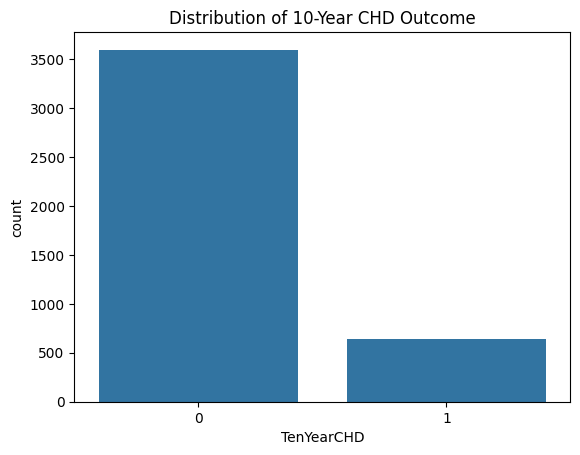

TenYearCHD
0    3596
1     644
Name: count, dtype: int64


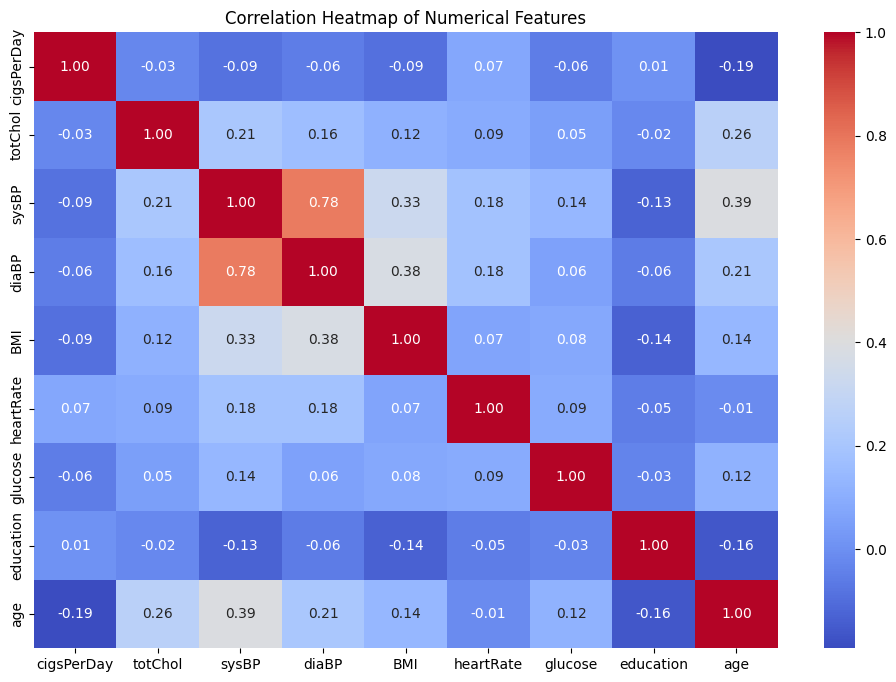

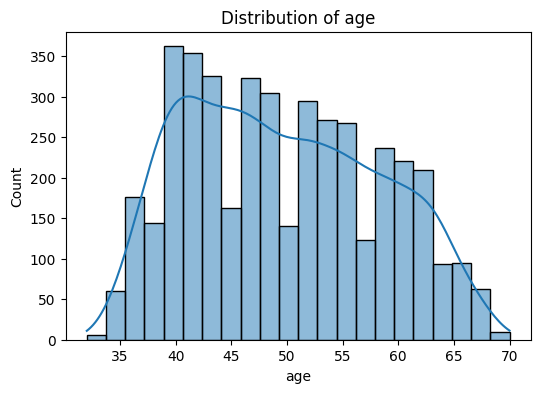

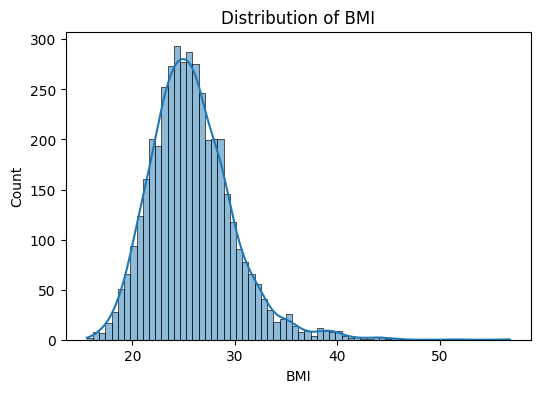

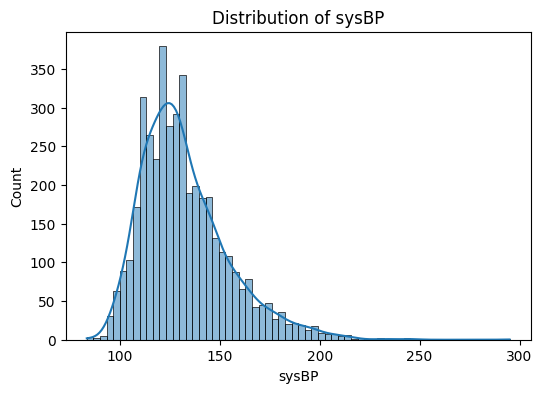

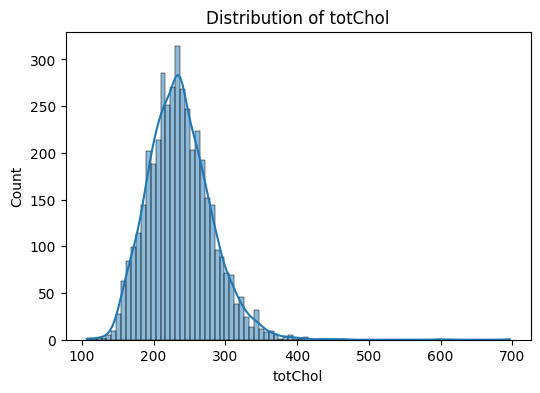

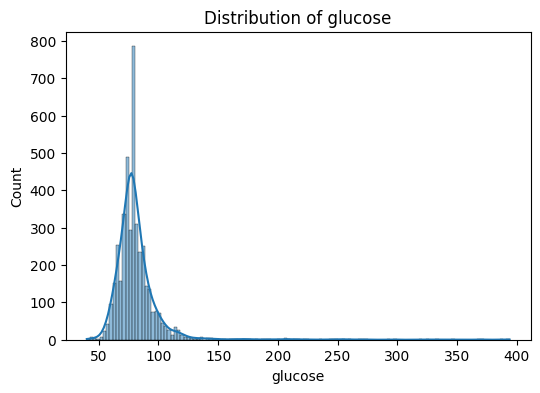

In [6]:
# Target distribution
sns.countplot(x="TenYearCHD", data=df)
plt.title("Distribution of 10-Year CHD Outcome")
plt.show()
print(df["TenYearCHD"].value_counts())

# Correlation heatmap
corr = df[num_cols + ["age"]].corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

# Histograms for key features
features_to_plot = ["age", "BMI", "sysBP", "totChol", "glucose"]
for feature in features_to_plot:
    plt.figure(figsize=(6,4))
    sns.histplot(df[feature], kde=True)
    plt.title(f"Distribution of {feature}")
    plt.show()

## 4. Feature Preparation
Encode categorical features as numeric codes and define target variable.

In [7]:
# Drop target from features
target = 'TenYearCHD'
features = df.drop(columns=[target])

# Encode categorical features
cat_cols = ['male', 'currentSmoker', 'BPMeds', 'prevalentStroke',
            'prevalentHyp', 'diabetes']
for col in cat_cols:
    features[col] = features[col].cat.codes

# Target as numeric
y = df[target].cat.codes

## 5. Train/Test Split and Scaling
Split dataset into training and testing sets and apply standard scaling.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 80/20 split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    features, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: (3392, 15)
Test set: (848, 15)


## 6. Modelling: Logistic Regression, Random Forest, XGBoost
Train three models and store them in a dictionary for iteration.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Define models
lr = LogisticRegression(random_state=42, max_iter=1000)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
xgb = XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)

# Dictionary to loop through
models = {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb}

## 7. Model Evaluation
Evaluate models using accuracy, ROC-AUC, confusion matrix, and classification report.

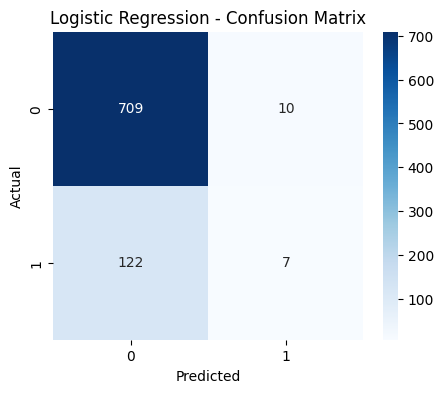

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.99      0.91       719
           1       0.41      0.05      0.10       129

    accuracy                           0.84       848
   macro avg       0.63      0.52      0.51       848
weighted avg       0.79      0.84      0.79       848



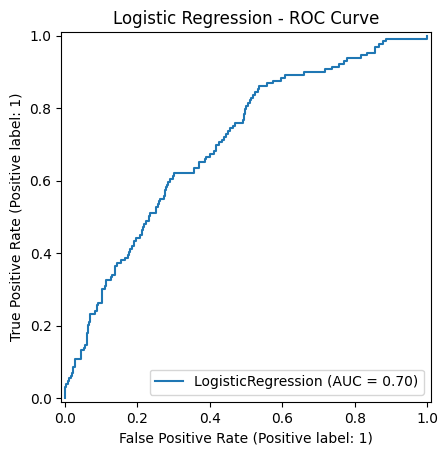

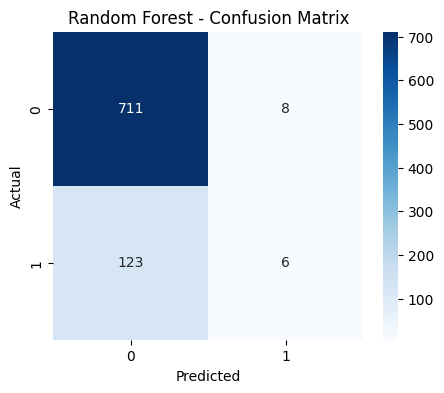

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.99      0.92       719
           1       0.43      0.05      0.08       129

    accuracy                           0.85       848
   macro avg       0.64      0.52      0.50       848
weighted avg       0.79      0.85      0.79       848



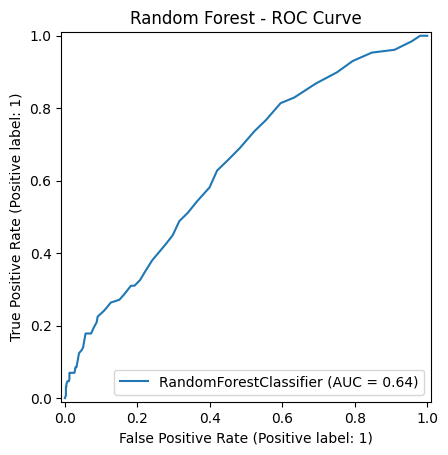

c:\Users\udumz\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:199: UserWarning: [12:30:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


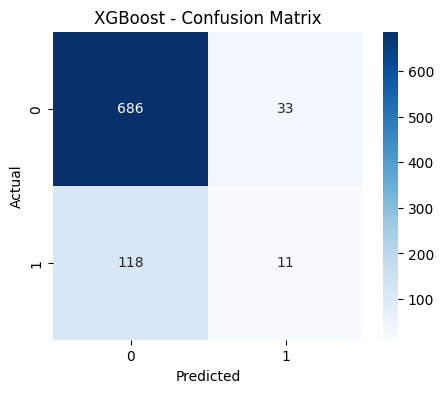

XGBoost Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.95      0.90       719
           1       0.25      0.09      0.13       129

    accuracy                           0.82       848
   macro avg       0.55      0.52      0.51       848
weighted avg       0.76      0.82      0.78       848



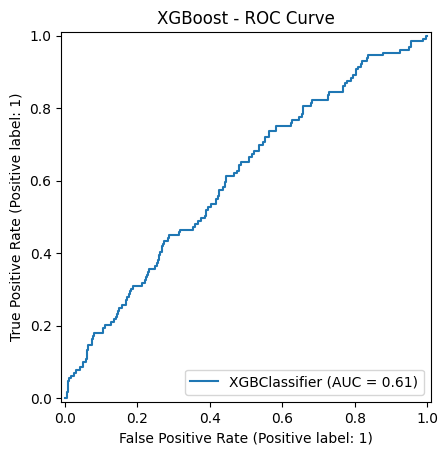

Model comparison:
                      Accuracy   ROC-AUC
Logistic Regression  0.844340  0.702192
Random Forest        0.845519  0.642020
XGBoost              0.821934  0.605039


In [10]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay

results = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predict
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:,1]
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    results[name] = {'Accuracy': acc, 'ROC-AUC': roc}
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    # Classification Report
    print(f"{name} Classification Report:\n")
    print(classification_report(y_test, y_pred))
    
    # ROC Curve
    RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)
    plt.title(f'{name} - ROC Curve')
    plt.show()

# Model comparison
results_df = pd.DataFrame(results).T
print("Model comparison:\n", results_df)

## 8. Feature Importance and SHAP Analysis
Analyse feature importance using Random Forest and SHAP.

c:\Users\udumz\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


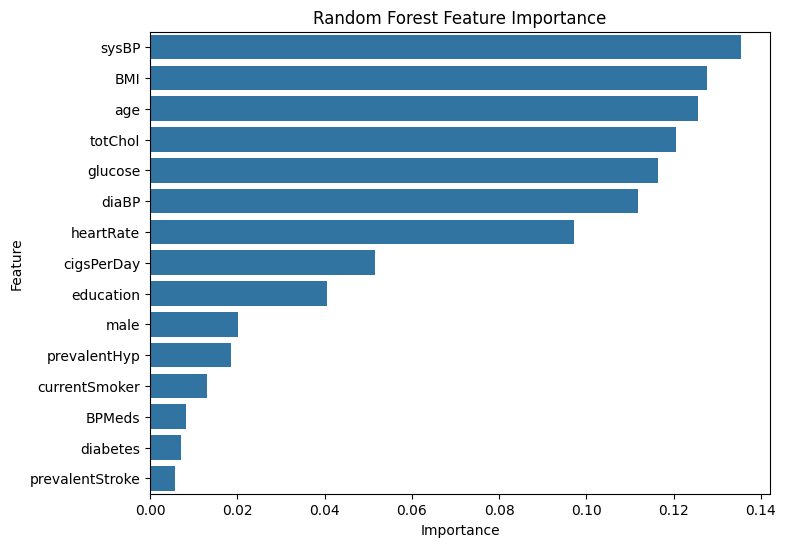

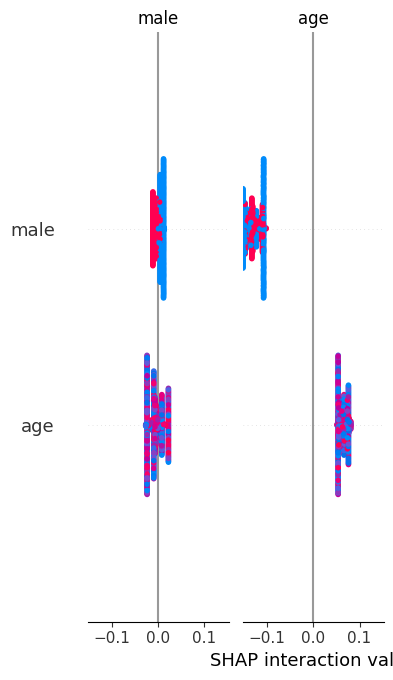

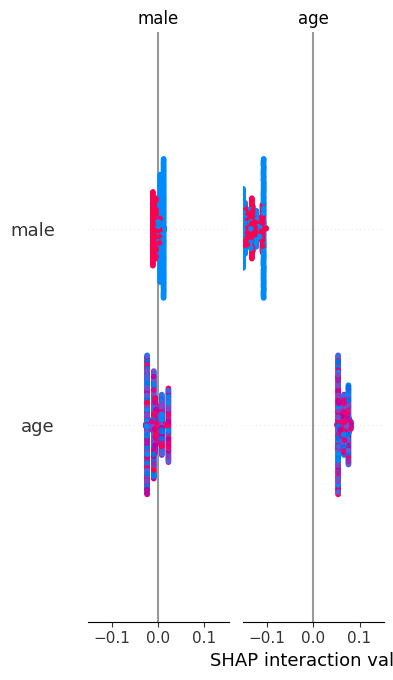

In [13]:
import shap

# Random Forest feature importance
rf_model = models['Random Forest']
importances = rf_model.feature_importances_
feature_names = X_train.columns

feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x='Importance', y='Feature', data=feat_imp)
plt.title('Random Forest Feature Importance')
plt.show()

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# Bar plot
shap.summary_plot(shap_values, X_test, plot_type="bar")

# Beeswarm plot
shap.summary_plot(shap_values, X_test)


# Save results
feat_imp.to_csv('feature_importance_rf.csv', index=False)
y_pred_df = pd.DataFrame({'Actual': y_test, 'Predicted': rf_model.predict(X_test_scaled)})
y_pred_df.to_csv('rf_predictions.csv', index=False)
